# Telecom Customer Churn Prediction

**Project Type:** Machine Learning Classification Project
**Goal:** Predict whether a telecom customer will churn (leave the company) or not, based on their account information, services used, and billing details.

Churn means a customer stopping their service. For telecom companies, keeping an old customer is much cheaper than getting a new one, so predicting churn early can help the company take action (like offering a discount) before the customer leaves.

In this notebook I will:
1. Load and explore the dataset
2. Clean the data
3. Do some visualizations (EDA)
4. Prepare the data for machine learning
5. Train a few different classification models
6. Compare the models and pick the best one
7. Save the final model so it can be used later in the Streamlit app


## 1. Importing the libraries we need

In [1]:
# basic libraries for handling data
import pandas as pd
import numpy as np

# libraries for plotting graphs
import matplotlib.pyplot as plt
import seaborn as sns

# libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# to save the trained model
import pickle

# just to make the graphs look a bit nicer
sns.set_style("whitegrid")
%matplotlib inline


## 2. Loading the dataset

The dataset is the popular **Telco Customer Churn** dataset (IBM sample dataset). Each row is one customer, and the columns describe the services they use, their account info, and whether they churned or not.


In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")

# how many rows and columns do we have?
print("Shape of the data:", df.shape)

df.head()


Shape of the data: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Basic exploration of the data

In [4]:
# summary statistics of the numeric columns
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
# checking how many customers churned vs not churned
df['Churn'].value_counts()


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
# same thing but in percentage, this shows the data is a bit imbalanced
df['Churn'].value_counts(normalize=True) * 100


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## 4. Checking and fixing missing values

At first glance `isnull().sum()` shows 0 missing values everywhere. But if we look closely at the `TotalCharges` column, it is stored as text (object) instead of numbers. That is usually a sign that some values are blank spaces `" "` instead of actual numbers.


In [7]:
print(df.isnull().sum())
print()
print("Data type of TotalCharges:", df['TotalCharges'].dtype)


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data type of TotalCharges: str


In [8]:
# let's see how many rows have a blank TotalCharges value
blank_rows = df[df['TotalCharges'].str.strip() == ""]
print("Number of blank TotalCharges values:", len(blank_rows))
blank_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]


Number of blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [9]:
# all these blank rows have tenure = 0, which means they are brand new customers
# who haven't been billed yet. So it makes sense to set their TotalCharges to 0.

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# double check it worked
print(df['TotalCharges'].isnull().sum(), "missing values left")
print(df['TotalCharges'].dtype)


0 missing values left
float64


In [10]:
# customerID is just a unique code for each customer, it doesn't help the model
# so we can drop it
df = df.drop('customerID', axis=1)
df.shape


(7043, 20)

## 5. Exploratory Data Analysis (EDA)

Let's visualize the data to understand what factors might be related to churn.

### 5.1 Churn distribution

/tmp/ipykernel_618/1027167793.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


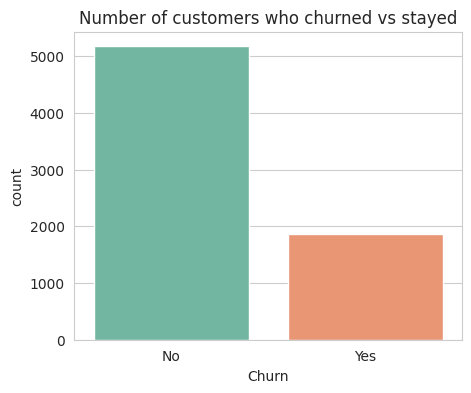

In [11]:
plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Number of customers who churned vs stayed')
plt.show()


### 5.2 Churn by contract type

Month-to-month customers are usually the ones most likely to leave since they have no long term commitment.

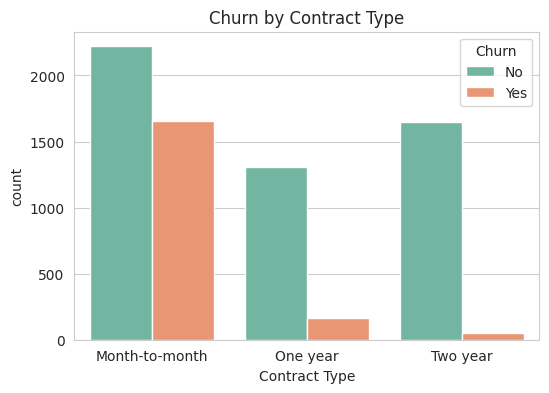

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x='Contract', hue='Churn', data=df, palette='Set2')
plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.show()


### 5.3 Churn by tenure

Tenure is how many months the customer has been with the company.

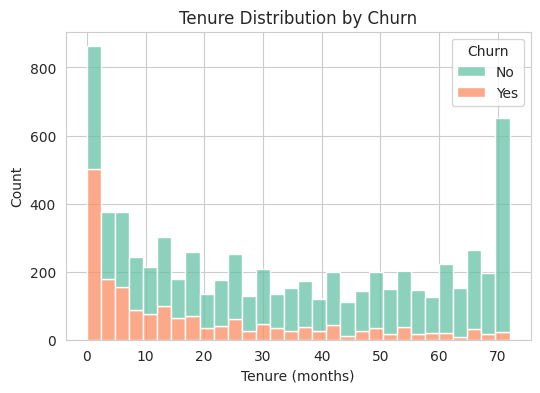

In [13]:
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=False, multiple='stack', palette='Set2')
plt.title('Tenure Distribution by Churn')
plt.xlabel('Tenure (months)')
plt.show()


### 5.4 Churn by monthly charges

/tmp/ipykernel_618/3476678549.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette='Set2')


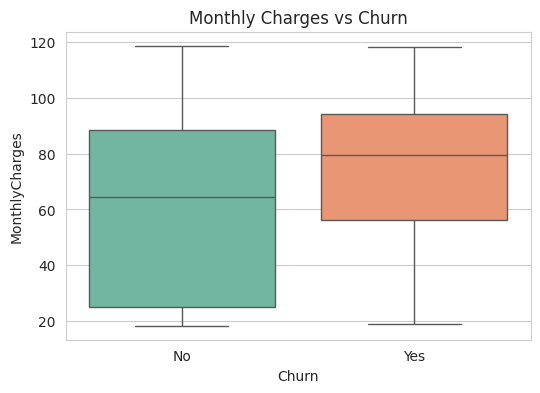

In [14]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette='Set2')
plt.title('Monthly Charges vs Churn')
plt.show()


### 5.5 Churn by Internet Service type

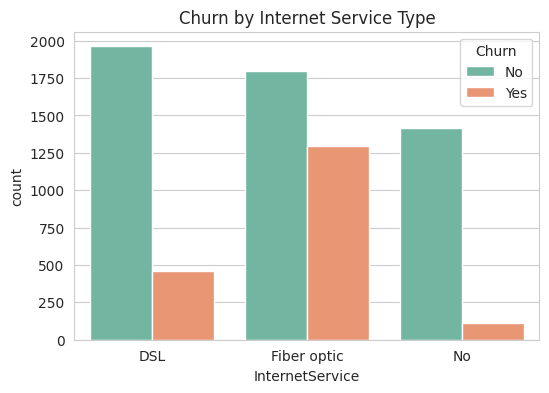

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(x='InternetService', hue='Churn', data=df, palette='Set2')
plt.title('Churn by Internet Service Type')
plt.show()


### 5.6 Quick observations from EDA

- Customers on **month-to-month** contracts churn a lot more than customers on one/two year contracts.
- Customers with **lower tenure** (new customers) churn more than long-time customers.
- Customers with **higher monthly charges** tend to churn slightly more.
- Customers with **Fiber optic** internet churn more than DSL or no internet customers.

These are useful patterns and we expect the ML model to pick up on similar patterns.


## 6. Preparing the data for Machine Learning

Machine learning models only understand numbers, not text like "Yes"/"No" or "Month-to-month". So we need to convert all the categorical (text) columns into numbers using **Label Encoding**.


In [16]:
# first let's convert the target column: Yes -> 1, No -> 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

df['Churn'].value_counts()


Churn
0    5174
1    1869
Name: count, dtype: int64

In [17]:
# find all the remaining text (categorical) columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", categorical_cols)


Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


/tmp/ipykernel_618/4042362050.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns.tolist()


In [18]:
# use LabelEncoder to convert each categorical column into numbers
# we save each encoder in a dictionary so we can reuse the SAME encoding
# later in the Streamlit app

encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le   # save it for later use

df.head()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [19]:
# just to see what the encoding looks like for one column, for example 'Contract'
list(zip(encoders['Contract'].classes_, encoders['Contract'].transform(encoders['Contract'].classes_)))


[('Month-to-month', np.int64(0)),
 ('One year', np.int64(1)),
 ('Two year', np.int64(2))]

### 6.1 Correlation heatmap

Now that everything is numeric, we can check how each column is correlated with Churn.

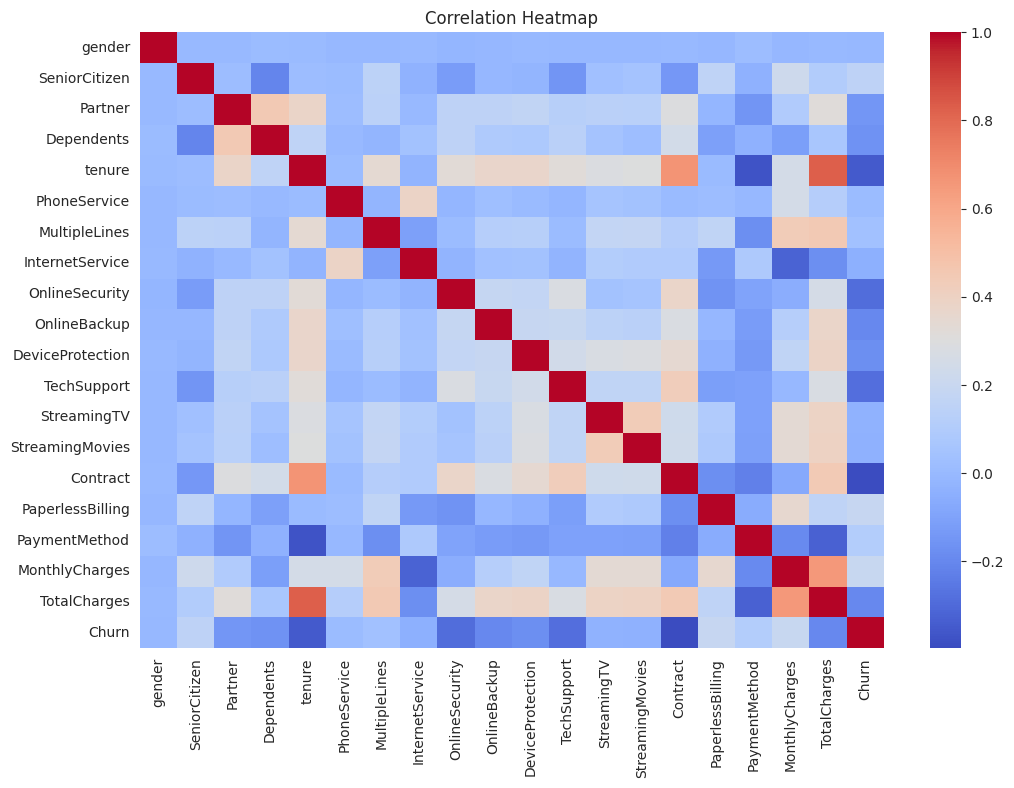

In [20]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap')
plt.show()


In [21]:
# correlation of every column with Churn, sorted
df.corr()['Churn'].sort_values(ascending=False)


Churn               1.000000
MonthlyCharges      0.193356
PaperlessBilling    0.191825
SeniorCitizen       0.150889
PaymentMethod       0.107062
MultipleLines       0.038037
PhoneService        0.011942
gender             -0.008612
StreamingTV        -0.036581
StreamingMovies    -0.038492
InternetService    -0.047291
Partner            -0.150448
Dependents         -0.164221
DeviceProtection   -0.178134
OnlineBackup       -0.195525
TotalCharges       -0.198324
TechSupport        -0.282492
OnlineSecurity     -0.289309
tenure             -0.352229
Contract           -0.396713
Name: Churn, dtype: float64

## 7. Splitting the data into training and testing sets

We use 80% of the data to train the model and keep 20% aside to test how well it performs on data it hasn't seen before.


In [22]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (5634, 19)
Testing set size: (1409, 19)


## 8. Feature Scaling

Some columns like `tenure`, `MonthlyCharges`, and `TotalCharges` have much bigger numbers than the other 0/1 encoded columns. Scaling puts everything on a similar range, which helps models like Logistic Regression and KNN perform better.


In [23]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 9. Training different models

I will train 4 different classification models and compare their accuracy:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors (KNN)


### 9.1 Logistic Regression

In [24]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

log_preds = log_model.predict(X_test_scaled)
log_acc = accuracy_score(y_test, log_preds)

print("Logistic Regression Accuracy:", round(log_acc, 4))
print()
print(classification_report(y_test, log_preds))


Logistic Regression Accuracy: 0.7984

              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



### 9.2 Decision Tree

In [25]:
tree_model = DecisionTreeClassifier(max_depth=6, random_state=42)
tree_model.fit(X_train_scaled, y_train)

tree_preds = tree_model.predict(X_test_scaled)
tree_acc = accuracy_score(y_test, tree_preds)

print("Decision Tree Accuracy:", round(tree_acc, 4))
print()
print(classification_report(y_test, tree_preds))


Decision Tree Accuracy: 0.7842

              precision    recall  f1-score   support

           0       0.84      0.87      0.86      1035
           1       0.60      0.55      0.57       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.71      1409
weighted avg       0.78      0.78      0.78      1409



### 9.3 Random Forest

In [26]:
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
rf_model.fit(X_train_scaled, y_train)

rf_preds = rf_model.predict(X_test_scaled)
rf_acc = accuracy_score(y_test, rf_preds)

print("Random Forest Accuracy:", round(rf_acc, 4))
print()
print(classification_report(y_test, rf_preds))


Random Forest Accuracy: 0.7963

              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1035
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### 9.4 K-Nearest Neighbors (KNN)

In [27]:
knn_model = KNeighborsClassifier(n_neighbors=9)
knn_model.fit(X_train_scaled, y_train)

knn_preds = knn_model.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_preds)

print("KNN Accuracy:", round(knn_acc, 4))
print()
print(classification_report(y_test, knn_preds))


KNN Accuracy: 0.7665

              precision    recall  f1-score   support

           0       0.83      0.86      0.84      1035
           1       0.57      0.51      0.54       374

    accuracy                           0.77      1409
   macro avg       0.70      0.68      0.69      1409
weighted avg       0.76      0.77      0.76      1409



## 10. Comparing all the models

In [28]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN'],
    'Accuracy': [log_acc, tree_acc, rf_acc, knn_acc]
})

results = results.sort_values(by='Accuracy', ascending=False)
results


,Model,Accuracy
0,Logistic Regression,0.798439
2,Random Forest,0.796309
1,Decision Tree,0.784244
3,KNN,0.766501


/tmp/ipykernel_618/1772259010.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Accuracy', y='Model', data=results, palette='Set2')


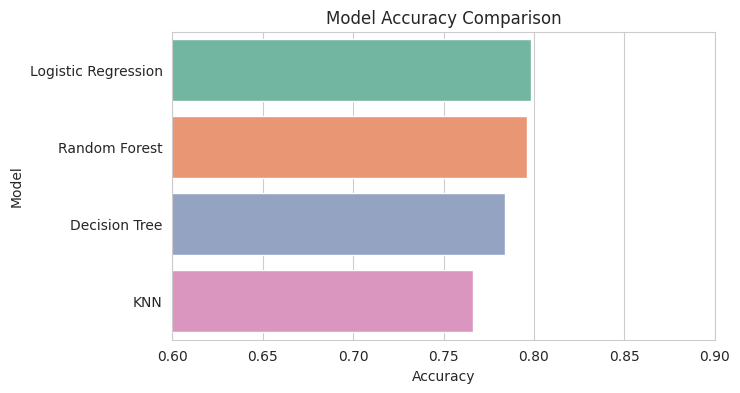

In [29]:
plt.figure(figsize=(7,4))
sns.barplot(x='Accuracy', y='Model', data=results, palette='Set2')
plt.title('Model Accuracy Comparison')
plt.xlim(0.6, 0.9)
plt.show()


Logistic Regression and Random Forest usually perform the best on this dataset. I will go with **Logistic Regression** as the final model since it gives good accuracy and is simple + fast, which also makes it easier to explain to non-technical people (important for a business use case like churn).

You can change `final_model` below to any of the other trained models if you want to experiment.


In [30]:
final_model = log_model   # <-- change this line to try a different model
final_model_name = "Logistic Regression"

final_preds = final_model.predict(X_test_scaled)
print("Final model:", final_model_name)
print("Accuracy:", round(accuracy_score(y_test, final_preds), 4))


Final model: Logistic Regression
Accuracy: 0.7984


### 10.1 Confusion Matrix of the final model

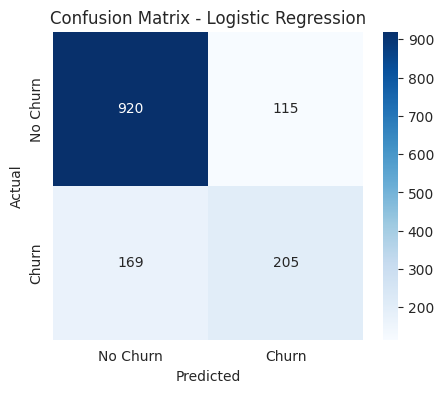

In [31]:
cm = confusion_matrix(y_test, final_preds)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {final_model_name}')
plt.show()


## 11. Which features matter the most?

Since Random Forest gives feature importance out of the box, let's use it to see which columns are the biggest drivers of churn (even though our final model is Logistic Regression, this is useful for insight).


/tmp/ipykernel_618/3036695793.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


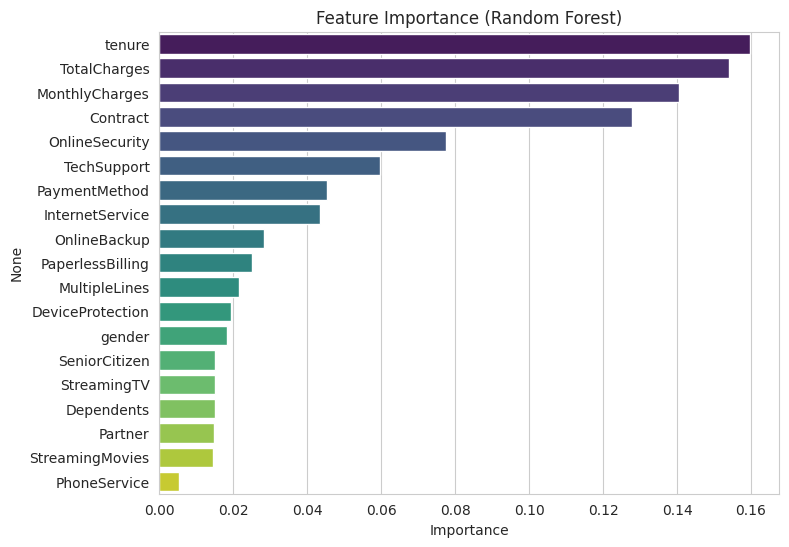

In [32]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.show()


## 12. Saving the model

We save 3 things so the Streamlit app can use them later:
1. The trained model
2. The scaler (so new input data is scaled the same way)
3. The label encoders (so text inputs like "Yes"/"No" are converted the same way as during training)


In [33]:
import os
os.makedirs('../models', exist_ok=True)

with open('../models/churn_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

with open('../models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('../models/encoders.pkl', 'wb') as f:
    pickle.dump(encoders, f)

with open('../models/columns.pkl', 'wb') as f:
    pickle.dump(list(X.columns), f)

print("Model, scaler, encoders and column order saved successfully!")


Model, scaler, encoders and column order saved successfully!


## 13. Conclusion

- We cleaned the data (fixed `TotalCharges`, dropped `customerID`).
- We did EDA and found that **contract type, tenure, and monthly charges** are strongly related to churn.
- We trained 4 models and compared them. Logistic Regression gave a good balance of accuracy and simplicity.
- The model, scaler, and encoders are saved and ready to be used in the Streamlit web app for real-time predictions.

### Possible future improvements
- Try handling class imbalance better (e.g. SMOTE) since churned customers are fewer than non-churned.
- Try hyperparameter tuning with GridSearchCV.
- Try more advanced models like XGBoost.
